# Gas kinematics of MaNGA 8244-12704

An undergraduate galaxy-kinematics project completed at UCL, presented as a single-galaxy analysis of spatially resolved spectra. How does the ionised gas trace rotation, and how does that rotation compare with an idealised exponential disc?

The saved results were validated by a complete fresh-kernel run in Python 3.13.15. The analysis uses spectrum inspection, joint H-alpha–[N II] fitting, velocity mapping, major-axis extraction and an illustrative light-profile/disc comparison. Selected additional lines provide exploratory diagnostics.

Cube loading, array transposition, WCS conversion, masking and narrow-band plotting adapt the [SDSS MaNGA Python tutorial](https://www.sdss4.org/dr17/manga/manga-tutorials/how-do-i-look-at-my-data/python). The author developed the fitting and modelling workflow. See `data/README.md` for the input cube and `README.md` for setup, results and limitations.

## Spectrum inspection

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize
from scipy import stats
from scipy import ndimage
from matplotlib import cm
from astropy import wcs
from astropy.io import fits
from astropy.cosmology import WMAP9 as cosmo
import astropy.units as u
from scipy.special import iv, kv  # for modified Bessel I_n, K_n


In [2]:
cube = fits.open('data/manga-8244-12704-LOGCUBE.fits.gz')    #run from the public project root

# reading in and re-ordering FLUX, IVAR, and MASK arrays from (wavelength, y, x) to (x, y, wavelength).
flux = np.transpose(cube['FLUX'].data, axes=(2, 1, 0))
ivar = np.transpose(cube['IVAR'].data, axes=(2, 1, 0))
mask = np.transpose(cube['MASK'].data, axes=(2, 1, 0))

wave = cube['WAVE'].data   #reading in wavelength
flux_header = cube['FLUX'].header   #reading in the header of the flux extension

In [3]:
# central spectrum of the datacube
x_center = int(flux_header['CRPIX1']) - 1   #finding the middle pixel in x
y_center = int(flux_header['CRPIX2']) - 1   #finding the middle pixel in y

plt.plot(wave, flux[x_center, y_center], linewidth=0.5)
plt.xlabel('wavelength (Ang)')
plt.ylabel(flux_header['BUNIT'])
plt.title('Spectrum at centre')
plt.show()

In [4]:
cubeWCS = wcs.WCS(flux_header)
ra = 133.035323408   #desired RA
dec = 51.3127390765  #desired dec
x_cube_coord, y_cube_coord, __ = cubeWCS.wcs_world2pix([[ra, dec, 1.]], 1)[0]
x_spaxel = int(np.round(x_cube_coord)) - 1  #corresponding x spaxel position
y_spaxel = int(np.round(y_cube_coord)) - 1  #corresponding x spaxel position

In [5]:
# Exclude the existing DONOTUSE bit (bit 10); other bits are unchanged.
do_not_use = (mask & 2**10) != 0   #finding the bad spaxels
flux_m = np.ma.array(flux, mask=do_not_use)  #new masked flux array
# flux error = 1/sqrt(ivar)
ivar_m = np.ma.array(ivar, mask = do_not_use)
flux_error = 1/np.sqrt(ivar_m)
# check print(np.shape(flux_m_error))

def valid_spectrum(x, y, selection):
    """Return aligned ordinary arrays for valid samples in the requested window."""
    wavelength = np.asarray(wave[selection])
    spectrum = flux_m[x, y][selection]
    inverse_variance = np.asarray(ivar[x, y][selection])
    values = np.asarray(np.ma.getdata(spectrum))
    valid = (~np.ma.getmaskarray(spectrum)
             & np.isfinite(wavelength) & np.isfinite(values)
             & np.isfinite(inverse_variance) & (inverse_variance > 0))
    return (wavelength[valid], values[valid],
            1 / np.sqrt(inverse_variance[valid]))


def signal_to_noise(signal, uncertainty):
    """Return NaN where the signal/error cannot define a valid S/N."""
    signal, uncertainty = np.broadcast_arrays(signal, uncertainty)
    result = np.full(signal.shape, np.nan, dtype=float)
    valid = (np.isfinite(signal) & np.isfinite(uncertainty)
             & (uncertainty > 0))
    np.divide(signal, uncertainty, out=result, where=valid)
    return result


### H-alpha

The adopted vacuum rest wavelength is 6564.6 Angstrom.

In [6]:
redshift = 0.115137  #redshift of this galaxy
dredshift = 0.000019
def emissionlinemap(min,max):
    ind_wave = np.where((wave / (1 + redshift) > min) & (wave / (1 + redshift) < max))[0]  #finding the wavelegth range around H$\alpha$
    halpha = flux_m[:, :, ind_wave].sum(axis=2)   #summing the fluxes at each spaxel in the wavelength range
    im = halpha.T

    # Convert from array indices to arcsec relative to IFU center
    dx = flux_header['CD1_1'] * 3600.  # deg to arcsec
    dy = flux_header['CD2_2'] * 3600.  # deg to arcsec
    x_extent = (np.array([0., im.shape[0]]) - (im.shape[0] - x_center)) * dx * (-1)
    y_extent = (np.array([0., im.shape[1]]) - (im.shape[1] - y_center)) * dy
    extent = [x_extent[0], x_extent[1], y_extent[0], y_extent[1]]
    plt.imshow(im, cmap=cm.YlGnBu_r, vmin=0.1, vmax=12, origin='lower', interpolation='none') #,
    plt.colorbar(label=flux_header['BUNIT'])
    plt.xlabel('spaxels')
    plt.ylabel('spaxels')
    plt.show()

In [7]:
# spectrum zoom to check the range of wavelength
def rangecheck(wavelength,width):
    # use central spectrum because it should have minimum rotational velocity
    # hence spectral line wavelength after removing red shift should be more accurate than other parts
    range = np.where((wave/(1 + redshift)>(wavelength-width)) & (wave/(1 + redshift)<(wavelength+width)))
    plt.errorbar(wave[range]/(1 + redshift), flux_m[x_center, y_center][range],yerr=flux_error[x_center, y_center][range],fmt='.-', linewidth=0.5)
    plt.xlabel('wavelength (Ang)')
    plt.ylabel(flux_header['BUNIT'])
    plt.show()

In [8]:
plt.title('Ha range check')
rangecheck(6564.6,25)

In [9]:
# note to avoid including NII emission line of 6549.9
# try to estimate the width of the emission line
plt.title('H alpha=6564.6A Emission Line Map')
emissionlinemap(6557,6573)

### [N II] doublet

The adopted vacuum rest wavelengths are 6549.9 and 6585.3 Angstrom.

In [10]:
rangecheck(6549.9,25)

In [11]:
# avoid H alpha line
# try to estimate the width of the emission line
plt.title('[NII]=6549.9A Emission Line Map')
emissionlinemap(6542,6557)

In [12]:
rangecheck(6585.3,25)

In [13]:
# avoid H alpha line
# try to estimate the width of the emission line
plt.title('[NII]=6585.3A Emission Line Map')
emissionlinemap(6575,6595)

### Additional spectral-window inspection

This narrow-band inspection is a diagnostic only; it is not used in the rotation or disc modelling.

In [14]:
rangecheck(3728.3,25)

In [15]:
# try to estimate the width of the emission line
plt.title('[OII]=3728.3A Emission Line Map')
emissionlinemap(3722,3734)

### [O III] doublet

The adopted vacuum rest wavelengths are 4960.3 and 5008.2 Angstrom.

In [16]:
plt.title('OIII=4960.3A range check for central spaxel')
rangecheck(4960.3,25)

In [17]:
# too weak at the centre, check outer region of galaxy in ds9, somewhere OIII seem more apparent 
# somewhere else from ds9
range_O3 = np.where((wave/(1 + redshift)>(4960.3-25)) & (wave/(1 + redshift)<(4960.3+25)))
plt.errorbar(wave[range_O3]/(1 + redshift), flux_m[33,19][range_O3], yerr=flux_error[33,19][range_O3], fmt='.-', linewidth=0.5)
plt.xlabel('wavelength (Ang)')
plt.ylabel(flux_header['BUNIT'])
plt.title('[OIII]=4960.3A good location range check')
plt.show()

An off-centre spectrum provides a diagnostic of the weaker [O III] line. Its centroid can differ from the adopted systemic-redshift position because of line-of-sight motion.

In [18]:
# try to estimate the width of the emission line
plt.title('[OIII]=4960.3A Emission Line Map')
emissionlinemap(4955,4965)

In [19]:
rangecheck(5008.2,15)

In [20]:
# try to estimate the width of the emission line
plt.title('[OIII]=5008.2A Emission Line Map')
emissionlinemap(5001,5014)

### [S II]

The selected line has an adopted vacuum rest wavelength of 6718.3 Angstrom.

In [21]:
rangecheck(6718.3,25)

In [22]:
# try to estimate the width of the emission line
plt.title('[SII]=6718.3A Emission Line Map')
emissionlinemap(6711,6725)

## Joint H-alpha–[N II] fitting

Three Gaussian components share a redshift and width, with independent amplitudes and a constant continuum. Only finite, unmasked samples with positive finite inverse variance enter the optimiser. The central spectrum provides a fit diagnostic; its fitted redshift is 0.115145 and Gaussian width is 3.77 Angstrom.

In [23]:
# rest wavelengths of H alpha and 2 NII lines are constants
wl_Ha_rest = 6564.6
wl_NII1_rest = 6549.9
wl_NII2_rest = 6585.3

In [24]:
def Gaussian(wl_obs, C, sig, z, A_Ha, A_NII1, A_NII2):
    '''fitting single spaxel with good S/N spectrum using Gaussian
    Args: 
    wl_obs (Ang): observed wavelength 
    C: flux of the continuum, offset
    z: red shift of the galaxy 
    sig: line dispersion, sets the width of the peaks
    A_Ha, NII1, NII2: peak values of H alpha and 2 NII lines
    returns: flux (counts)
    '''
    flux = C + A_Ha*np.exp(-(wl_obs-wl_Ha_rest*(1+z))**2/(2*sig**2)) + A_NII1*np.exp(-(wl_obs-wl_NII1_rest*(1+z))**2/(2*sig**2)) + A_NII2*np.exp(-(wl_obs-wl_NII2_rest*(1+z))**2/(2*sig**2))
    return flux

In [25]:
# range for wavelengths
# 100 Ang around H_a (red shift corrected, estimated from galaxy red shift)
range_vm = np.where((wave>(wl_Ha_rest*(1+redshift)-100)) & (wave<(wl_Ha_rest*(1+redshift)+100)))
wave_vm, flux_vm, dflux_vm = valid_spectrum(x_center, y_center, range_vm)
if wave_vm.size < 6:
    raise ValueError("Fewer valid samples than joint-fit parameters at the centre.")
plt.plot(wave_vm, flux_vm)
plt.xlabel('wavelength (Ang)')
plt.ylabel(flux_header['BUNIT'])
plt.show()

In [26]:
# continuum flux
C_g = stats.mode(flux_vm)
print(C_g[0])
# peak values
A_ha_g = np.max(flux_vm)
print(A_ha_g)
# NII take half of Ha peak as guess 

In [27]:
# curve fitting 
# guesses and values for the fitted parameters
# Initial width 3 Angstrom, bounded between 1 and 5 Angstrom
# minus offset for peak values
po = [C_g[0], 3, redshift, A_ha_g-C_g[0], A_ha_g/2-C_g[0], A_ha_g/2-C_g[0]]
# bounds
dA = 0.25 # for peak values and continuum
low_bound = [C_g[0]-dA, 1, redshift-1, A_ha_g-C_g[0]-dA, A_ha_g/2-C_g[0]-dA, A_ha_g/2-C_g[0]-dA]
up_bound = [C_g[0]+dA, 5, redshift+1, A_ha_g-C_g[0]+dA, A_ha_g/2-C_g[0]+dA, A_ha_g/2-C_g[0]+dA]
popt_centre,pcov_centre = optimize.curve_fit(Gaussian, wave_vm, flux_vm, p0=po, sigma = dflux_vm,  absolute_sigma=True, bounds=(low_bound, up_bound))

In [28]:
# values with their error
print("param 0-9: C, sig, z, A_Ha, A_NII1, A_NII2")
print("==================================================================================")
for i in range(6):
    unc_centre = np.sqrt(np.diag(pcov_centre))
    print(f'param_{i} = {popt_centre[i]:.6f} +- {unc_centre[i]:.6f}') 

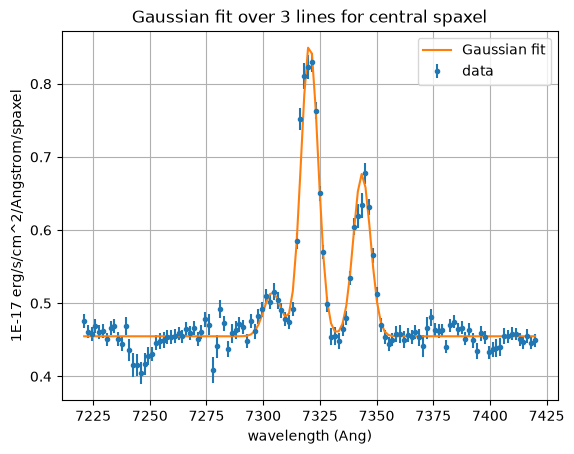

In [29]:
# overplot to check 
# curve 
line_shape_centre = Gaussian(wave_vm,popt_centre[0],popt_centre[1],popt_centre[2],popt_centre[3],popt_centre[4],popt_centre[5])
# plot 
plt.errorbar(wave_vm, flux_vm, yerr=dflux_vm,fmt='.', label = 'data') 
plt.plot(wave_vm, line_shape_centre, label = 'Gaussian fit')
plt.title("Gaussian fit over 3 lines for central spaxel")
plt.xlabel('wavelength (Ang)')
plt.ylabel(flux_header['BUNIT'])
plt.legend(loc = 'best')
plt.grid()

In [30]:
# define a function to do the fit to over different spaxels and the for loop later 
def gaussian_fit(x,y):
    """takes x,y values of spaxel and returns a gaussian fit for H alpha and NII lines for the spaxel"""
    range_vm = np.where((wave>(wl_Ha_rest*(1+redshift)-100)) & (wave<(wl_Ha_rest*(1+redshift)+100)))
    wave_vm, flux_vm, dflux_vm = valid_spectrum(x, y, range_vm)
    if wave_vm.size < 6:
        return np.nan, np.nan
    # change guess values for continuum C and peak value A 
    # continuum flux
    C_g = np.median(flux_vm)
    # peak values
    A_ha_g = np.max(flux_vm)
    po = [C_g, 3, redshift, A_ha_g, A_ha_g/2, A_ha_g/2]
    # bounds
    # redshift with 1000 km/s bounds
    low_bound = [0, 1, redshift-1000/3e5, 0, 0, 0]
    up_bound = [2*C_g, 5, redshift+1000/3e5, 3*A_ha_g, 1.5*A_ha_g, 1.5*A_ha_g]
    # curvefit
    try: 
        popt,pcov = optimize.curve_fit(Gaussian, wave_vm, flux_vm, p0=po, sigma = dflux_vm,  absolute_sigma=True, bounds=(low_bound, up_bound))
        unc = np.sqrt(np.diag(pcov))
        # overplot 
        # curve 
        line_shape = Gaussian(wave_vm,popt[0],popt[1],popt[2],popt[3],popt[4],popt[5])
        # plot 
        plt.errorbar(wave_vm, flux_vm, yerr=dflux_vm,fmt='.', label = 'data') 
        plt.plot(wave_vm, line_shape, label = 'Gaussian fit')
        plt.title("Gaussian fit over 3 lines")
        plt.xlabel('wavelength (Ang)')
        plt.ylabel(flux_header['BUNIT'])
        plt.legend(loc = 'best')
        plt.grid()
    except: 
        popt = np.nan
        unc = np.nan
    return popt, unc

In [31]:
# check on centre spaxel to produce same result as before 
popt_centre, unc_centre = gaussian_fit(x_center,y_center)

In [32]:
# function for for loop 
def gaussian_fit_for_loop(x,y):
    """takes x,y values of spaxel and returns a gaussian fit for H alpha and NII lines for the spaxel"""
    wave_vm, flux_vm, dflux_vm = valid_spectrum(x, y, range_vm)
    if wave_vm.size < 6:
        return np.nan, np.nan
    # change guess values for continuum C and peak value A 
    # continuum flux
    C_g = np.median(flux_vm)
    # peak values
    A_ha_g = np.max(flux_vm)
    po = [C_g, 3, redshift, A_ha_g, A_ha_g/2, A_ha_g/2]
    # bounds
    # redshift with 1000 km/s bounds
    low_bound = [0, 1, redshift-1000/3e5, 0, 0, 0]
    up_bound = [2*C_g, 5, redshift+1000/3e5, 3*A_ha_g, 1.5*A_ha_g, 1.5*A_ha_g]
    # curvefit 
    try: 
        popt,pcov = optimize.curve_fit(Gaussian, wave_vm, flux_vm, p0=po, sigma = dflux_vm,  absolute_sigma=True, bounds=(low_bound, up_bound))
        unc = np.sqrt(np.diag(pcov))
    except: 
        popt = np.nan
        unc = np.nan
    return popt, unc

In [33]:
# for loop
popt_all = np.zeros([(74*74),6])
unc_all = np.zeros([(74*74),6])
c=0
for i in range(74):
    for k in range(74): 
        popt_temp, unc_temp = gaussian_fit_for_loop(k,i)
        popt_all[c,:] = popt_temp
        unc_all[c,:] = unc_temp
        c=c+1

In [34]:
popt_xy = np.reshape(popt_all, (74, 74, 6))
unc_xy = np.reshape(unc_all, (74, 74, 6))

In [35]:
# get z to plot velocity map 
z_all= popt_xy[:, :, 2]
dz_all = unc_xy[:, :, 2]
np.shape(z_all)

In [36]:
# exclude spaxels with low S/N 
# AHa / dAHa > 5, ANII/dANII > 3, AHa > 3 x dC 
# range_GSN = np.where((popt_all[:,3]/unc_all[:,3]>5) & (popt_all[:,4]/unc_all[:,4]>3) & (popt_all[:,3]>3*unc_all[:,0]))
mask = (signal_to_noise(popt_xy[:,:,3], unc_xy[:,:,3])>5) & (signal_to_noise(popt_xy[:,:,5], unc_xy[:,:,5])>3) & (popt_xy[:,:,3]>3*unc_xy[:,:,0])
z_G = np.where(mask,z_all,np.nan)
dz_G = np.where(mask,dz_all,np.nan)
# print(range_GSN)
# z_G = z_all[range_GSN[0],range_GSN[1]]
np.shape(z_G)

In [37]:
# Galaxy-rest-frame velocity, retaining the existing c approximation in km/s.
c_kms = 3*100000
def rest_frame_velocity(z, dz):
    velocity = c_kms * (z - redshift) / (1 + redshift)
    # Independent marginal errors in fitted z and adopted systemic z.
    error = np.sqrt((c_kms * dz / (1 + redshift))**2
                    + (c_kms * (1 + z) * dredshift / (1 + redshift)**2)**2)
    return velocity, error

v_G, dv_G = rest_frame_velocity(z_G, dz_G)
# The systemic contribution is shared across spaxels, not independent fit noise.


In [38]:
plt.figure(figsize = [7,7])
plt.imshow(v_G, cmap=cm.RdBu_r, vmin = -300, vmax = 300,origin='lower', interpolation='nearest')
plt.colorbar(label='Velocity (km/s)')
plt.title('Velocity map')
plt.xlabel('spaxels')
plt.ylabel('spaxels')
plt.show()

## Integrated line-flux map

For a Gaussian with amplitude A and width sigma, the continuum-subtracted integrated flux is A sigma sqrt(2 pi). The H-alpha map below uses numerical flux units of 10^-17 erg s^-1 cm^-2 per spaxel. Narrow-band sums elsewhere are inspection diagnostics, not this fitted line-flux estimator.

In [39]:
sig_all = popt_xy[:,:,1]
A_Ha_all= popt_xy[:, :, 3]
A_NII1_all= popt_xy[:, :, 4]
A_NII2_all= popt_xy[:, :, 5]

F_Ha_tot = A_Ha_all*sig_all*np.sqrt(2*np.pi)
F_NII1_tot = A_NII1_all*sig_all*np.sqrt(2*np.pi)
F_NII2_tot = A_NII2_all*sig_all*np.sqrt(2*np.pi)

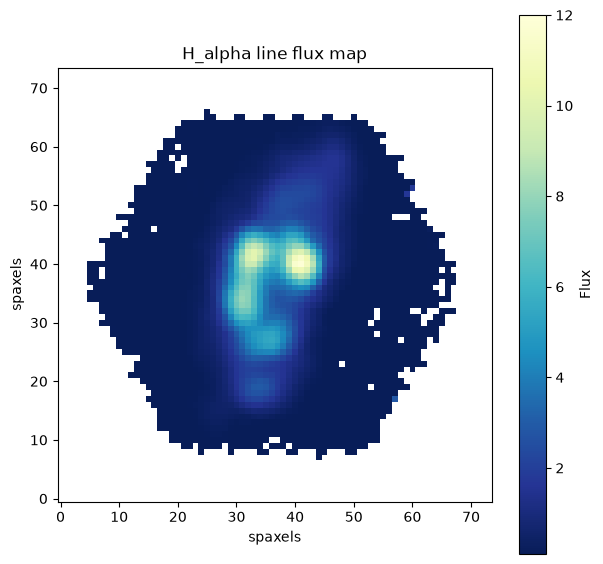

In [40]:
plt.figure(figsize = [7,7])
plt.imshow(F_Ha_tot, cmap=cm.YlGnBu_r, vmin = 0.1, vmax = 12, origin='lower', interpolation='nearest')
plt.colorbar(label='Flux')
plt.title('H_alpha line flux map')
plt.xlabel('spaxels')
plt.ylabel('spaxels')
plt.show()

In [41]:
plt.figure(figsize = [7,7])
plt.imshow(F_NII1_tot, cmap=cm.YlGnBu_r,  vmin = 0.1, vmax = 12, origin='lower', interpolation='nearest')
plt.colorbar(label='Flux')
plt.title('[NII]=6549.9A line flux map')
plt.xlabel('spaxels')
plt.ylabel('spaxels')
plt.show()

In [42]:
plt.figure(figsize = [7,7])
plt.imshow(F_NII2_tot, cmap=cm.YlGnBu_r,  vmin = 0.1, vmax = 12, origin='lower', interpolation='nearest')
plt.colorbar(label='Flux')
plt.title('[NII]=6585.3A line flux map')
plt.xlabel('spaxels')
plt.ylabel('spaxels')
plt.show()

### Signal-to-noise selection

Integrated-flux uncertainty uses independent amplitude and width variances, converted to a standard uncertainty; amplitude–width covariance is neglected. S/N is NaN for nonfinite or nonpositive uncertainty. The peak-S/N velocity map retains 1,176 spaxels. The integrated-flux diagnostic retains 648, all in its largest connected component. Rotation extraction uses the peak-S/N map (`v_G`), with the adopted thresholds preserved.

In [43]:
# dF
dsig_all = unc_xy[:,:,1]
dA_Ha_all= unc_xy[:, :, 3]
dA_NII1_all= unc_xy[:, :, 4]
dA_NII2_all= unc_xy[:, :, 5]

dF_Ha_tot = np.sqrt(2*np.pi*sig_all**2*dA_Ha_all**2+2*np.pi*A_Ha_all**2*dsig_all**2)
dF_NII1_tot = np.sqrt(2*np.pi*sig_all**2*dA_NII1_all**2+2*np.pi*A_NII1_all**2*dsig_all**2)
dF_NII2_tot = np.sqrt(2*np.pi*sig_all**2*dA_NII2_all**2+2*np.pi*A_NII2_all**2*dsig_all**2)

In [44]:
# exclude spaxels with low S/N 
# SN > 5, AHa > 3 x dC and red chi

main_mask = (signal_to_noise(F_Ha_tot, dF_Ha_tot)>5) & (signal_to_noise(F_NII2_tot, dF_NII2_tot)>5) & (signal_to_noise(F_NII1_tot, dF_NII1_tot)>5) & (popt_xy[:,:,3]>3*unc_xy[:,:,0])
z_G_F_1 = np.where(main_mask,z_all,np.nan)
dz_G_F_1 = np.where(main_mask,dz_all,np.nan)
# print(range_GSN)
# z_G = z_all[range_GSN[0],range_GSN[1]]
np.shape(z_G)

In [45]:
v_G_F_1, dv_G_F_1 = rest_frame_velocity(z_G_F_1, dz_G_F_1)


In [46]:
plt.figure(figsize = [7,7])
plt.imshow(v_G_F_1, cmap=cm.RdBu_r, vmin = -300, vmax = 300,origin='lower', interpolation='nearest')
plt.colorbar(label='Velocity (km/s)')
plt.title('Velocity map')
plt.xlabel('spaxels')
plt.ylabel('spaxels')
plt.show()

In [47]:
# only keep main body
# label each connected area
labels, nlab = ndimage.label(main_mask)
# area of each 
sizes = ndimage.sum(main_mask, labels, index=range(1, nlab+1))
# label of the largest area
main_label = np.argmax(sizes) + 1
sec_mask = labels == main_label

In [48]:
final_mask = main_mask&sec_mask
z_G_F = np.where(final_mask,z_all,np.nan)
dz_G_F = np.where(final_mask,dz_all,np.nan)
v_G_F, dv_G_F = rest_frame_velocity(z_G_F, dz_G_F)


In [49]:
plt.figure(figsize = [7,7])
plt.imshow(v_G_F, cmap=cm.RdBu_r, vmin = -300, vmax = 300,origin='lower', interpolation='nearest')
plt.colorbar(label='Velocity (km/s)')
plt.title('Velocity map')
plt.xlabel('spaxels')
plt.ylabel('spaxels')
plt.show()

## Major-axis extraction and rotation profile

The adopted endpoints are (30,14) and (47,64), with 30 rounded sample pixels in zero-based image coordinates. Define e = (17,50)/sqrt(2789) and s = 1 + (p-p1) dot e, in spaxels. The positive coordinate permits the empirical model f(s) = (a-d)/(1+(s/q)^b)+d; q alone is constrained positive in the unweighted fit.

The fitted half-transition defines centre_xy = p1 + (q-1)e and v_centre = (a+d)/2. The centre must lie within the sampled interval. Signed physical displacement is (p-centre_xy) dot e, converted with the adopted pixel scale and distance. Observed and model curves are folded as absolute displacement and absolute (v-v_centre), then corrected by sin(i). No further radial inclination correction is applied along the major axis.

For z_sys = 0.115137 and c_light = 300,000 km/s, v = c_light (z-z_sys)/(1+z_sys). Independent marginal redshift errors give sigma_v^2 = [c_light/(1+z_sys)]^2 sigma_z^2 + [c_light(1+z)/(1+z_sys)^2]^2 sigma_zsys^2. The systemic error is shared across spaxels; treating every error bar independently does not capture that correlation.

The fitted centre is (37.640778,36.472877) spaxels and the residual velocity centre is +9.429825 km/s. The folded error bars are conditional on that fitted centre; its covariance is not propagated. Rounded off-axis samples and absolute-value folding near zero are approximate. The empirical model depends on the declared positive-coordinate origin and is not necessarily reflection-symmetric, so branch separation alone does not establish intrinsic asymmetry.

In [50]:
# Preserve the adopted major axis through these two endpoints (zero-based pixels).
x1, y1, x2, y2 = 30,14,47,64
axis_start = np.array([x1, y1], dtype=float)
axis_end = np.array([x2, y2], dtype=float)
axis_length = np.linalg.norm(axis_end - axis_start)
axis_unit = (axis_end - axis_start) / axis_length
m = (y2-y1)/(x2-x1)
c = y1-m*x1
# Plot the same straight line used for extraction, with no invented middle point.
x = np.array([x1, x2])
y = np.array([y1, y2])
# Positive fitting coordinate for the original power-law logistic model.
axis_offset = 1.0 # spaxel; coordinate origin is one spaxel before axis_start


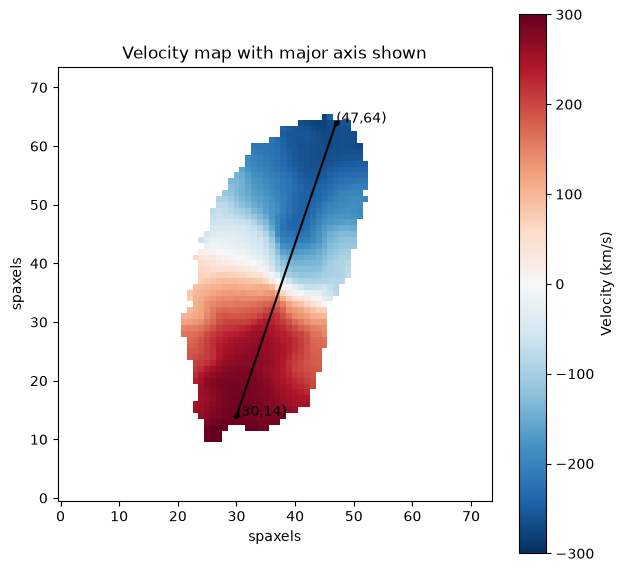

In [51]:
# overplot
plt.figure(figsize = [7,7])
plt.plot(x,y,'.-',color='black')
plt.imshow(v_G, cmap=cm.RdBu_r, vmin = -300, vmax = 300,origin='lower', interpolation='none') #,
plt.colorbar(label='Velocity (km/s)')
plt.text(30,14,'(30,14)')
plt.text(47,64,'(47,64)')
plt.title('Velocity map with major axis shown')
plt.xlabel('spaxels')
plt.ylabel('spaxels')
plt.show()


In [52]:
# x and y along the line
# estimate step size in spaxels
# lin space
xi = np.linspace(x1,x2,30)
yi = m*xi+c

xn_l = np.rint(xi).astype(int)
yn_l = np.rint(yi).astype(int)
v_los_l = v_G[yn_l,xn_l]
dv_los_l = dv_G[yn_l,xn_l]

In [53]:
# Project the actual rounded sample coordinates onto the adopted major axis.
sample_xy = np.column_stack((xn_l, yn_l))
axis_distance_l = (sample_xy - axis_start) @ axis_unit
s_0_l = axis_distance_l + axis_offset
if np.any(s_0_l <= 0):
    raise ValueError("The empirical model requires a positive fitting coordinate.")


In [54]:
# error bar values must be positive
plt.errorbar(s_0_l,v_los_l,yerr=np.abs(dv_los_l), fmt = 'x-')
plt.title('line-of-sight velocity along major axis')
plt.xlabel('Positive along-axis fitting coordinate (spaxels)')
plt.ylabel('Velocity (km/s)')
plt.show()


In [55]:
def vlos(s,a,b,c,d):
    """Original empirical model on positive along-axis coordinate s (spaxels).

    c > 0 is the half-transition coordinate, where v=(a+d)/2.
    This is a descriptive profile, not a dynamical mass model.
    """
    vlos = ((a-d)/(1+(s/c)**b))+d
    return vlos


In [56]:
# Same unweighted fitting strategy and empirical model; update the coordinate guess.
po_vlos = [1, 1, axis_offset + axis_length/2, 2]
# Positive c is mathematically necessary for real non-integer powers on positive s.
los_lower = [-np.inf, -np.inf, np.finfo(float).eps, -np.inf]
los_upper = [np.inf, np.inf, np.inf, np.inf]
if not np.all(np.isfinite(v_los_l)):
    raise ValueError("An adopted major-axis sample failed the unchanged peak-S/N selection.")
popt_los_l,pcov_los_l = optimize.curve_fit(
    vlos, s_0_l, v_los_l, p0=po_vlos, absolute_sigma=True,
    bounds=(los_lower, los_upper))
if not np.min(s_0_l) < popt_los_l[2] < np.max(s_0_l):
    raise ValueError("The fitted half-transition centre lies outside the sampled axis.")


In [57]:
unc = np.sqrt(np.diag(pcov_los_l))
print(popt_los_l)

[ 280.17892461    8.37488319   24.73629452 -261.31927549]


In [58]:
# overplot
s_plot_l = np.sort(np.append(np.linspace(np.min(s_0_l), np.max(s_0_l), 1000), popt_los_l[2]))
v_plot_l = vlos(s_plot_l,popt_los_l[0],popt_los_l[1], popt_los_l[2], popt_los_l[3])
plt.plot(s_plot_l,v_plot_l,'r-', label = 'fitted')
plt.errorbar(s_0_l,v_los_l,yerr=np.abs(dv_los_l), fmt='+', label = 'measured')
plt.title('line-of-sight velocity along major axis')
plt.xlabel('Positive along-axis fitting coordinate (spaxels)')
plt.ylabel('Velocity (km/s)')
plt.legend(loc = 'best')
plt.show()


In [59]:
# Define the kinematic centre by the empirical model's half-transition point.
s_cen_l = popt_los_l[2]
v_cen_l = (popt_los_l[0]+popt_los_l[3])/2
centre_xy = axis_start + (s_cen_l - axis_offset) * axis_unit
print("Fitted centre (x, y), zero-based spaxels:", centre_xy)
print("Residual velocity centre relative to adopted systemic redshift (km/s):", v_cen_l)


Fitted centre (x, y), zero-based spaxels: [37.64077808 36.47287672]
Residual velocity centre relative to adopted systemic redshift (km/s): 9.429824562088243


In [60]:
# Signed projected distance from the fitted point on the adopted axis, in spaxels.
s_frmcen_l = (sample_xy - centre_xy) @ axis_unit


In [61]:
# Use the SAME fitted velocity centre for observed and model curves.
vlos_fold_l = np.abs(v_los_l - v_cen_l)
s_fold_l = np.abs(s_frmcen_l)
s_plot_fold_l = np.abs(s_plot_l - s_cen_l)
v_plot_fold_l = np.abs(v_plot_l - v_cen_l)
# Error bars below are conditional on the fitted centre; no centre-fit covariance
# or folding-boundary distribution is propagated in this portfolio approximation.


In [62]:
plt.errorbar(s_fold_l,vlos_fold_l,yerr=np.abs(dv_los_l), fmt='+', label = 'measured')
plt.plot(s_plot_fold_l,v_plot_fold_l,'r-', label = 'fitted')
plt.title('Centred, folded major-axis velocity')
plt.xlabel('Along-axis distance from fitted centre (spaxels)')
plt.ylabel('absolute velocity (km/s)')
plt.legend(loc = 'best')
plt.show()


In [63]:
# inclination
i_deg, di_deg = 65.07, 0.04
# in radian as np functions in radian
i, di = np.deg2rad(65.07), np.deg2rad(0.04)
# Marginal velocity/inclination errors, conditional on the fitted spatial/velocity centre.
v_cr_l = vlos_fold_l/np.sin(i)
dv_cr_l = np.sqrt((vlos_fold_l*(-np.cos(i)/(np.sin(i)**2))*di)**2+(dv_los_l/np.sin(i))**2)
v_cr_plot_l = v_plot_fold_l/np.sin(i)
dv_cr_plot_l = np.cos(i)/np.sin(i)*di*v_cr_plot_l
rs_kpcas = cosmo.arcsec_per_kpc_proper(redshift)
s_kpc_l = (s_fold_l*0.5*u.arcsec/rs_kpcas).to(u.kpc)
s_kpc_plot_l = (s_plot_fold_l*0.5*u.arcsec/rs_kpcas).to(u.kpc)
print(rs_kpcas)
print(dv_cr_l)


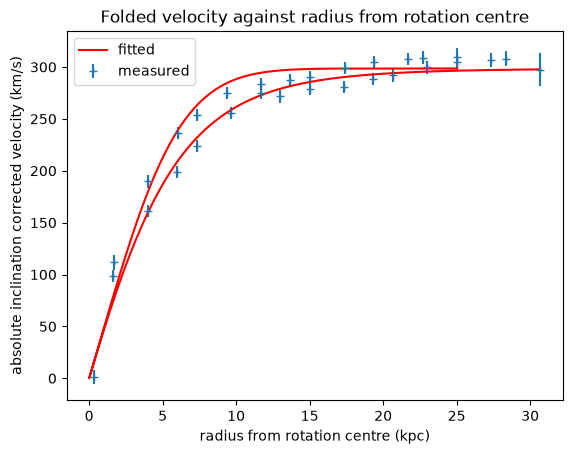

In [64]:
plt.errorbar(s_kpc_l,v_cr_l,yerr=dv_cr_l, fmt='+', label = 'measured')
plt.plot(s_kpc_plot_l,v_cr_plot_l,'r-', label = 'fitted')
plt.title('Folded velocity against radius from rotation centre')
plt.xlabel('radius from rotation centre (kpc)')
plt.ylabel('absolute inclination corrected velocity (km/s)')
plt.legend(loc = 'best')
plt.show()

## Surface brightness and illustrative stellar disc

The observed continuum band corresponds to rest-frame 7000–8000 Angstrom. Bin edges are reconstructed at midpoints in log wavelength, with boundary bins clipped to the exact band. For valid unmasked samples, F_band = sum(f_lambda,j delta_lambda_j) and sigma_F^2 = sum(delta_lambda_j^2 / IVAR_j). Input flux density is in 10^-17 erg s^-1 cm^-2 Angstrom^-1 per spaxel, so integrated flux is in 10^-17 erg s^-1 cm^-2 per spaxel. Missing bins are not extrapolated. All 30 sampled profiles have complete valid-band coverage in this run.

The exponential profile fits flux per projected physical kpc^2. For a transparent thin disc, A_disc = A_projected/cos(i), hence J0 = 4 pi d_L^2 I0 10^-17 cos(i), with d_L in cm and J0 in erg s^-1 kpc^-2 of disc-plane area. The major-axis length scale is unaffected by this area conversion. The fitted Re is 16.43277 kpc and Rd = Re/1.678 is 9.79307 kpc.

This section is an **illustrative model comparison**, not a calibrated stellar-mass measurement or definitive dark-matter determination. LM = 0.1 is an assumed scaling against the adopted solar-luminosity constant; a restricted band is not bolometric luminosity. The model neglects gas, bulge, dust, thickness and PSF effects. The approximate disc error does not include full covariance propagation and is not a reliable confidence interval.

The Sersic function adapts the author's earlier Python work. The exponential-disc model follows equations attributed to Cimatti, Fraternali & Nipoti (2019), *Introduction to Galaxy Formation and Evolution*.

In [65]:
# Integrate the same rest-frame 7000--8000 Angstrom band in observed wavelength.
# MaNGA LOGCUBE supplies bin centres; infer log-bin edges at half log spacing.
log_wave = np.log(wave)
if not np.all(np.isfinite(log_wave)) or np.any(np.diff(log_wave) <= 0):
    raise ValueError("Wavelength centres must be finite, positive and increasing.")
log_edges = np.empty(wave.size + 1)
log_edges[1:-1] = (log_wave[:-1] + log_wave[1:]) / 2
log_edges[0] = log_wave[0] - (log_wave[1] - log_wave[0]) / 2
log_edges[-1] = log_wave[-1] + (log_wave[-1] - log_wave[-2]) / 2
wave_edges = np.exp(log_edges)
band_lo, band_hi = 7000*(1 + redshift), 8000*(1 + redshift)
# Clip edge bins to the requested band; weights are observed Angstrom.
band_widths = np.maximum(0.0, np.minimum(wave_edges[1:], band_hi)
                        - np.maximum(wave_edges[:-1], band_lo))
ind_wave = np.flatnonzero(band_widths > 0)
weights = band_widths[ind_wave]
band_flux = np.asarray(np.ma.getdata(flux_m[:, :, ind_wave]))
band_ivar = np.asarray(ivar[:, :, ind_wave])
band_valid = (~np.ma.getmaskarray(flux_m[:, :, ind_wave])
              & np.isfinite(band_flux) & np.isfinite(band_ivar) & (band_ivar > 0))
band_variance = np.zeros_like(band_ivar, dtype=float)
np.divide(1.0, band_ivar, out=band_variance, where=band_valid)
band_flux_m = np.ma.array(band_flux, mask=~band_valid)
band_variance_m = np.ma.array(band_variance, mask=~band_valid)
fluxprofile = (band_flux_m * weights).sum(axis=2).T
dfluxprofile = np.ma.sqrt((band_variance_m * weights**2).sum(axis=2)).T
# Diagnostic only: no new coverage threshold or missing-bin extrapolation.
band_coverage = (band_valid * weights).sum(axis=2).T / (band_hi - band_lo)

plt.imshow(fluxprofile, cmap=cm.YlGnBu_r, origin='lower', interpolation='none')
plt.colorbar(label='Band flux (1E-17 erg/s/cm^2 per spaxel)')
plt.title('Observed-band flux corresponding to rest 7000--8000 Angstrom')
plt.xlabel('spaxels')
plt.ylabel('spaxels')
plt.show()


In [66]:
plt.plot(x,y,'.-',color='black')
plt.imshow(fluxprofile, cmap=cm.YlGnBu_r, origin='lower', interpolation='none') #,
plt.colorbar(label='1E-17 erg/s/cm^2/spaxel')
plt.xlabel('spaxels')
plt.ylabel('spaxels')
plt.show()

In [67]:
## extract surface brightness profile along the major axis ##
# x and y along the line from previous part
# extract flux first
fluxprofile_l = fluxprofile[yn_l,xn_l]
# error 
dfluxprofile_l = dfluxprofile[yn_l,xn_l]
spaxscale = (0.5*u.arcsec/rs_kpcas).to(u.kpc) # physical size of one spaxel
area_spax = (spaxscale**2).to_value(u.kpc**2) # numerical area in kpc^2
# surface brightness is flux per unit area 
sbprofile_l = fluxprofile_l / area_spax
dsbprofile_l = dfluxprofile_l / area_spax
# This is flux per projected kpc^2; disc-plane conversion is applied below.
print("Major-axis band coverage (fraction of requested width):", band_coverage[yn_l,xn_l])
# radius from galactic centre from before in kpc


In [68]:
plt.errorbar(s_kpc_l, sbprofile_l, yerr = dsbprofile_l, fmt = ".")
plt.title('Surface brightness profile along major axis')
plt.xlabel('radius from rotation centre (kpc)')
plt.ylabel('Projected flux density (1E-17 erg/s/cm^2/kpc^2)')
plt.show()


In [69]:
# Sersic profile, n = 1; adapted from the author's earlier Python work
def sersic(R, Ie, Re):
    '''arguments:
    R is the radius from centre of galaxy
    Re is the effective radius 
    Ie is the surface brightness at effective radius 
    bn coefficient depending on n
    returns: 
    surface brightness I '''
    n = 1
    # bn approximation from textbook
    bn = 2*n-1/3+4/(405*n)
    I = Ie * np.exp((-1*bn)*((R/Re)**(1/n)-1))
    return I

In [70]:
# Preserve the same weighted exponential fit and selected major-axis samples.
sb_values = np.asarray(np.ma.getdata(sbprofile_l))
sb_errors = np.asarray(np.ma.getdata(dsbprofile_l))
if (np.any(np.ma.getmaskarray(sbprofile_l))
        or np.any(np.ma.getmaskarray(dsbprofile_l))
        or not np.all(np.isfinite(sb_values))
        or not np.all(np.isfinite(sb_errors) & (sb_errors > 0))):
    raise ValueError("Invalid continuum-profile samples; review coverage before fitting.")
popt_sb_l,pcov_sb_l = optimize.curve_fit(
    sersic, s_kpc_l.to_value(u.kpc), sb_values,
    sigma=sb_errors, absolute_sigma=True)


In [71]:
unc_sb_l = np.sqrt(np.diag(pcov_sb_l))
print(popt_sb_l, unc_sb_l)

[84.59095585 16.43276968] [0.05579952 0.01453486]


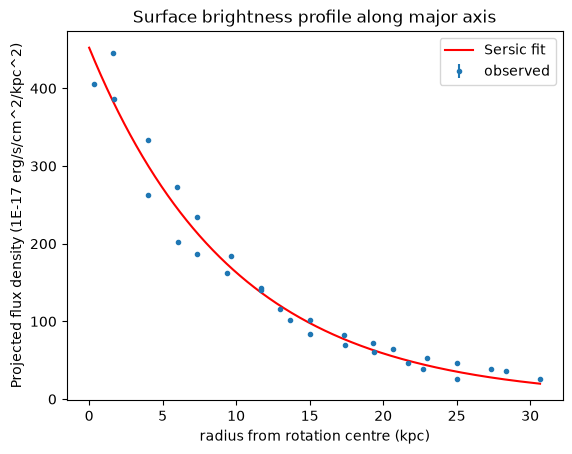

In [72]:
# overplot 
s_plot = np.linspace(0,np.max(s_kpc_l).value, 1000)
sb_plot = sersic(s_plot,popt_sb_l[0], popt_sb_l[1])
plt.plot(s_plot,sb_plot,'r-', label = 'Sersic fit')
plt.errorbar(s_kpc_l, sbprofile_l, yerr = dsbprofile_l, fmt = ".", label = 'observed')
plt.title('Surface brightness profile along major axis')
plt.xlabel('radius from rotation centre (kpc)')
plt.ylabel('Projected flux density (1E-17 erg/s/cm^2/kpc^2)')
plt.legend(loc = 'best')
plt.show()


In [73]:
# disc scale length
# Re = 1.678 Rd of a pure exponential disk [textbook]
Rd = popt_sb_l[1]/1.678
dRd = unc_sb_l[1]/popt_sb_l[1]*Rd
# peak surface brightness 
I0 = sersic(0,popt_sb_l[0], popt_sb_l[1])
dI0 = unc_sb_l[0]/popt_sb_l[0]*I0
print ('Rd = ', Rd,'+-',dRd, 'kpc; I0 = ', I0, '+-',dI0, '1E-17 erg/s/cm^2/kpc^2')

Rd =  9.793068938129114 +- 0.008662011350510649 kpc; I0 =  452.31125766168617 +- 0.2983622896636709 1E-17 erg/s/cm^2/kpc^2


In [74]:
# luminosity distance 
dL = cosmo.luminosity_distance(redshift)
print(dL)
# convert to cm for later
dL_cm = dL.to(u.cm)
print(dL_cm)

In [75]:
# I0 is integrated band flux per PROJECTED physical area, in units of 1E-17.
# Transparent thin disc: A_disc = A_projected / cos(i), so multiply by cos(i).
I0_projected_luminosity = I0*1e-17*4*np.pi*(dL_cm.value**2)
I0intrinsic = I0_projected_luminosity * np.cos(i) # band erg/s per disc-plane kpc^2
# Retain only the existing photometric normalisation error, conditional on i and dL.
# Full disc uncertainty propagation (including inclination/covariances) is deferred.
dI0intrinsic = dI0*1e-17*4*np.pi*(dL_cm.value**2) * np.cos(i)
print("Disc-plane central band luminosity density:", I0intrinsic, "erg/s/kpc^2")
print("Conditional photometric normalisation error:", dI0intrinsic)


Disc-plane central band luminosity density: 6.681444337834919e+40 erg/s/kpc^2
Conditional photometric normalisation error: 4.407343388273261e+37


In [76]:
# to better see the trend extend radius to 60 kpc
r_t = np.linspace(0,60,300)
# Enclosed luminosity of an exponential disc
L_R = 2*np.pi*I0intrinsic*Rd**2*(1-np.exp(-r_t/Rd)*(1+r_t/Rd))

In [77]:
plt.plot(r_t,L_R)
plt.title('Enclosed luminosity profile for a disc galaxy')
plt.xlabel('radius from rotation centre (kpc)')
plt.ylabel('Enclosed Luminosity (erg/s)')
plt.show()

In [78]:
# constants 
# G in SI units 
G_SI = 6.67430e-11 # m^3/kg s^2
L_S = 3.828*10**26*10**7 # solar luminosity in W to ergs
M_S = 1.98847*10**30 # solar mass in kg
kpc = 3.085677581*10**16 # km
# G conversion, we also want vel in km/s so leave 2 km in
# 10^-9 to km^3/kg s^2
G = G_SI*(10**(-9))/kpc*M_S  # kpc (km/s)^2/M_sun
print(G)

In [79]:
def vcprofile(LM,R):
    '''arguments: 
    returns: illustrative circular velocity and legacy approximate error'''
    # Illustrative mass scaling of the disc-plane BAND luminosity density.
    # LM is not a calibrated stellar light-to-mass measurement.
    # The returned uncertainty is the legacy approximation, not a confidence interval.
    # central surface density = mass per area 
    # L/M = I0/SD0
    # LM*L_S/M_S = I0/SD0
    SD0 = I0intrinsic/(LM*L_S) # in solar mass per kpc^2
    dSD0 = dI0intrinsic/I0intrinsic*SD0
    # y
    y = np.asarray(R)/(2*Rd)
    at_origin = (y == 0)
    y_eval = np.where(at_origin, 1.0, y)
    dy = dRd/Rd*y_eval
    # sq circular vel of exponential razor-thin disc
    vc2 = 4*np.pi*G*SD0*Rd*y_eval**2*(iv(0,y_eval)*kv(0,y_eval)-iv(1,y_eval)*kv(1,y_eval))
    # At fixed R=0, the exponential-disc velocity and its parameter error tend to zero.
    vc_dm = np.where(at_origin, 0.0, np.sqrt(vc2))
    # treat modified bessel functions as constant over y error range 
    # approximate its error by dy/y as well, 1/2 factor from sqrt
    dvc_dm = vc_dm/2*np.sqrt((dSD0/SD0)**2+(dRd/Rd)**2+9*(dy/y_eval)**2)
    dvc_dm = np.where(at_origin, 0.0, dvc_dm)
    return vc_dm, dvc_dm


In [80]:
vc_dm_60, dvc_dm_60 = vcprofile(0.1, r_t)
plt.plot(r_t,vc_dm_60)
plt.title('Illustrative exponential-disc curve (assumed normalisation)')
plt.xlabel('radius from rotation centre (kpc)')
plt.ylabel('Rotation velocity (km/s)')
plt.show()


In [81]:
# to compare with our measured velocity go back to range from before
r_plot = np.linspace(0,np.max(s_kpc_plot_l).value,300)
vc_dm_plot, dvc_dm_plot = vcprofile(0.1,r_plot)

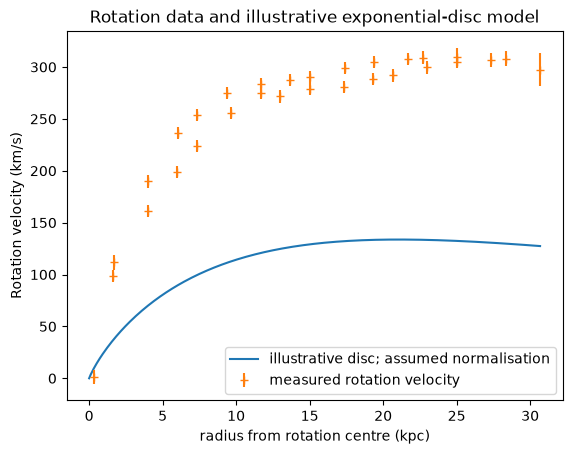

In [82]:
plt.plot(r_plot,vc_dm_plot, label = 'illustrative disc; assumed normalisation')
plt.errorbar(s_kpc_l,v_cr_l,yerr=dv_cr_l,fmt = '+', label = 'measured rotation velocity')
plt.title('Rotation data and illustrative exponential-disc model')
plt.xlabel('radius from rotation centre (kpc)')
plt.ylabel('Rotation velocity (km/s)')
plt.legend(loc = 'best')
plt.show()


## Exploratory additional-line diagnostics

Selected [O III] and [S II] fits inherit the H-alpha-region redshift and width, then fit a local continuum and amplitude. Parent fits must have finite positive formal errors. The fixed width in Angstrom is an approximation. Detection uses amplitude divided by median pixel noise with the existing threshold of 3; no amplitude/fitted-error selection is imposed. These diagnostics are not a joint multi-line kinematic refit.

There are 86 detections for [O III] 4960.3, 1,448 for [O III] 5008.2 and 958 for [S II] 6718.3. The selected [S II] map illustrates the spatial structure after excluding an invalid parent fit.

In [83]:
wl_OII_rest = 3728.3 # strong
wl_OIII1_rest = 4960.3 # weaker
wl_OIII2_rest = 5008.2 # stronger
wl_SII_rest = 6718.3 # weak ish

In [84]:
def detect_and_fit_line(wl_rest, x, y, pm, snr_lim):
    """
    Fit a single emission line in one spaxel using fixed centre and width
    and include decision

    Args: 
    wl_rest: Rest wavelength of the emission line
    x,y: spaxel position 
    pm: Half-width of fitting range
    snr_lim: minimum S/N threshold for detection

    Returns:
    result:
        {
          'success': true false
          'detected': true false
          'continuum': data,
          'amplitude': data,
          'amplitude_err': data,
          'flux': data,
          'flux_err': data,
          'snr_amp': data,
          'snr_flux': data,
        }
    """

    wave_full = wave
    flux_full = flux_m
    flux_err_full = flux_error
    z = popt_xy[y,x,2]
    sig = popt_xy[y,x,1]
    dsig = unc_xy[y,x,1]

    parent_params = popt_xy[y, x]
    parent_errors = unc_xy[y, x]
    parent_fit_valid = (np.all(np.isfinite(parent_params))
                        and np.all(np.isfinite(parent_errors)
                                   & (parent_errors > 0)))
    # Observed wavelength from velocity of this spaxel
    wl_obs = wl_rest * (1.0 + z)
    
    # is wl_obs even in the wavelength range?
    if (not parent_fit_valid or not np.isfinite(wl_obs) or not np.isfinite(sig) or sig <= 0
            or (wl_obs < wave_full.min() - pm) or (wl_obs > wave_full.max() + pm)):
        return {
            'success': False,
            'detected': False,
            'continuum': np.nan,
            'amplitude': np.nan,
            'amplitude_err': np.nan,
            'flux': np.nan,
            'flux_err': np.nan,
            'snr_amp': np.nan,
            'snr_flux': np.nan
        }
    
    # wavelength range
    mask = (wave_full > wl_obs - pm) & (wave_full < wl_obs + pm)
    
    # If the mask has no True values, bail out
    if not np.any(mask):
        return {
            'success': False,
            'detected': False,
            'continuum': np.nan,
            'amplitude': np.nan,
            'amplitude_err': np.nan,
            'flux': np.nan,
            'flux_err': np.nan,
            'snr_amp': np.nan,
            'snr_flux': np.nan
        }
    wave_range, flux_fit, flux_err = valid_spectrum(x, y, mask)
    
    # too few points then exclude
    if wave_range.size < 5:
        return {
            'success': False,
            'detected': False,
            'continuum': np.nan,
            'amplitude': np.nan,
            'amplitude_err': np.nan,
            'flux': np.nan,
            'flux_err': np.nan,
            'snr_amp': np.nan,
            'snr_flux': np.nan
        }

    # Rough continuum + noise estimate
    cont_guess = np.median(flux_fit)
    # Use error directly if values valid, otherwise standard dev
    if np.all(np.isfinite(flux_err)) and np.any(flux_err > 0):
        noise_est = np.median(flux_err)
    else:
        noise_est = np.std(flux_fit - cont_guess)
    if noise_est == 0:
        noise_est = 1e-6 # avoid 0 error

    # Gaussian but fixed centre and width of peak
    def gauss_fix(w, C, A):
        return C + A * np.exp(-(w - wl_obs)**2 / (2 * sig**2))
    # Guard the selected local spectrum before taking its maximum.
    if flux_fit.size == 0 or not np.all(np.isfinite(flux_fit)):
        return {
            'success': False,
            'detected': False,
            'continuum': np.nan,
            'amplitude': np.nan,
            'amplitude_err': np.nan,
            'flux': np.nan,
            'flux_err': np.nan,
            'snr_amp': np.nan,
            'snr_flux': np.nan
        }
    # Initial guesses
    A0 = np.max(flux_fit) # - cont_guess
    p0 = [cont_guess, A0] # p0=p0,

    try:
        popt, pcov = optimize.curve_fit(gauss_fix, wave_range, flux_fit,sigma=flux_err,absolute_sigma=True,maxfev=10000)
    except Exception:
        return {
            'success': False,
            'detected': False,
            'continuum': np.nan,
            'amplitude': np.nan,
            'amplitude_err': np.nan,
            'flux': np.nan,
            'flux_err': np.nan,
            'snr_amp': np.nan,
            'snr_flux': np.nan
        }

    C_fit, A_fit = popt

    # Errors from covariance matrix if available
    if pcov is not None and np.all(np.isfinite(pcov)):
        A_err = np.sqrt(pcov[1, 1])
    else:
        A_err = np.nan

    # Integrated flux of Gaussian for the given emission line
    flux_fit = A_fit*np.sqrt(2*np.pi)*sig

    # flux error 
    dF = np.sqrt(2*np.pi*sig**2*A_err**2+2*np.pi*A_fit**2*dsig**2)
    # flux error estimated by noise * sqrt(N_core) * pixel size
    #core_mask = np.abs(wave - wl_obs) < 2.0 * sig
    #n_core = max(1, core_mask.sum())
    #dwl = np.median(np.diff(wave))
    #flux_err_est = noise_est * np.sqrt(n_core) * dwl

    # S/N
    snr_amp = A_fit / noise_est
    snr_flux = flux_fit / dF if dF > 0 else np.nan

    detected = bool((snr_amp > snr_lim) and (A_fit > 0))

    return {
        'success': True,
        'detected': detected,
        'continuum': C_fit,
        'amplitude': A_fit,
        'amplitude_err': A_err,
        'flux': flux_fit,
        'flux_err': dF,
        'snr_amp': snr_amp,
        'snr_flux': snr_flux
    }


In [85]:
# OIII1 line for loop
OIII1 = []
OIII1_flux = []
#c=0
for i in range(74):
    for k in range(74): 
        OIII1_temp = detect_and_fit_line(wl_OIII1_rest,k,i,15,3)
        if OIII1_temp['detected']:
            OIII1_flux_temp = OIII1_temp['flux']
        else:
            OIII1_flux_temp = np.nan
        OIII1.append(OIII1_temp)
        OIII1_flux.append(OIII1_flux_temp)
        #c=c+1

In [86]:
OIII1_xy = np.reshape(OIII1, (74, 74))
OIII1_flux_xy = np.reshape(OIII1_flux, (74, 74))

In [87]:
plt.figure(figsize = [7,7])
plt.imshow(OIII1_flux_xy, cmap=cm.YlGnBu_r,origin='lower', interpolation='nearest')
plt.colorbar(label='flux')
plt.title('OIII1 flux map with selected spaxels of good SN')
plt.xlabel('spaxels')
plt.ylabel('spaxels')
plt.show()

In [88]:
# OIII2 line for loop
OIII2 = []
OIII2_flux = []
#c=0
for i in range(74):
    for k in range(74): 
        OIII2_temp = detect_and_fit_line(wl_OIII2_rest,k,i,15,3)
        if OIII2_temp['detected']:
            OIII2_flux_temp = OIII2_temp['flux']
        else:
            OIII2_flux_temp = np.nan
        OIII2.append(OIII2_temp)
        OIII2_flux.append(OIII2_flux_temp)
        #c=c+1

In [89]:
OIII2_xy = np.reshape(OIII2, (74, 74))
OIII2_flux_xy = np.reshape(OIII2_flux, (74, 74))

In [90]:
plt.figure(figsize = [7,7])
plt.imshow(OIII2_flux_xy, cmap=cm.YlGnBu_r,origin='lower', interpolation='nearest')
plt.colorbar(label='flux')
plt.title('OIII2 flux map with selected spaxels of good SN')
plt.xlabel('spaxels')
plt.ylabel('spaxels')
plt.show()

In [91]:
# SII line for loop
SII = []
SII_flux = []
#c=0
for i in range(74):
    for k in range(74): 
        SII_temp = detect_and_fit_line(wl_SII_rest,k,i,15,3)
        if SII_temp['detected']:
            SII_flux_temp = SII_temp['flux']
        else:
            SII_flux_temp = np.nan
        SII.append(SII_temp)
        SII_flux.append(SII_flux_temp)
        #c=c+1

In [92]:
SII_xy = np.reshape(SII, (74, 74))
SII_flux_xy = np.reshape(SII_flux, (74, 74))

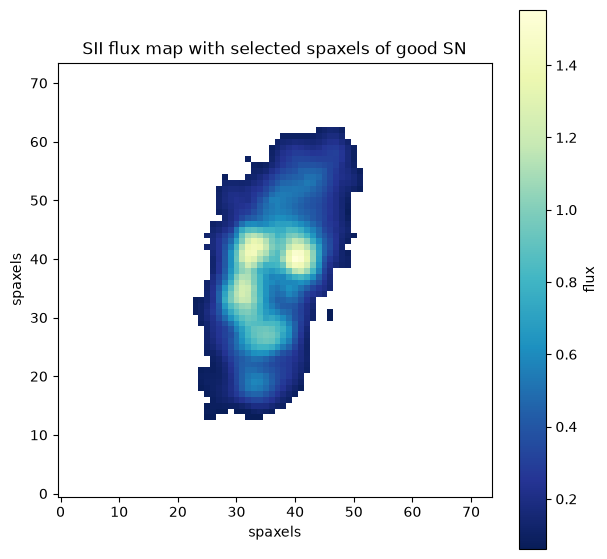

In [93]:
plt.figure(figsize = [7,7])
plt.imshow(SII_flux_xy, cmap=cm.YlGnBu_r,origin='lower', interpolation='nearest')
plt.colorbar(label='flux')
plt.title('SII flux map with selected spaxels of good SN')
plt.xlabel('spaxels')
plt.ylabel('spaxels')
plt.show()

## Results and attribution

The inclination-corrected asymptotic empirical speed is approximately 298.57 km/s. The disc-plane central band luminosity density is 6.68 x 10^40 erg s^-1 kpc^-2. With the assumed luminosity-to-mass scaling, the illustrative disc curve peaks near 133.71 km/s at 21.06 kpc. The gas rotation lies above that particular disc curve, but this comparison does not calibrate stellar mass or measure a dark-matter fraction.

Formal fit uncertainties are conditional and much smaller than the observed brightness-profile scatter. See the README for the adopted geometry, independent-error assumptions and physical omissions.

The validated run completed without numerical divide-by-zero warnings. Astropy emitted two input-header warnings when constructing the WCS: PLATEID was expected to be a string and MJD-OBS was filled from DATE-OBS. They did not interrupt execution; warning streams are omitted from the presentation.

Data: SDSS-IV MaNGA DR17, plate-IFU 8244-12704. Tutorial-derived loading, WCS, masking and inspection code is acknowledged above. All retained figures were generated by this analysis from the survey cube; no external figure is reproduced.